# SPX: From option quotes to a volatility smile

A volatility smile plots implied volatility against strike **for one expiry**. SPX often shows a downward skew: lower-strike puts have higher IV than higher-strike calls. These are prices of different payoffs expressed through a pricing model, rather than different physical volatilities of the same index.

We download Cboe's public **delayed option chain**, select OTM puts and calls, and invert their bid, midpoint and ask prices. This is a snapshot of quoted prices and sizes, not full order-book depth or executable real-time prices.

Sources: [Cboe quotes dashboard](https://www.cboe.com/delayed_quotes/spx/quote_table/), [public JSON endpoint](https://cdn.cboe.com/api/global/delayed_quotes/options/_SPX.json), [skew article](https://www.cboe.com/insights/posts/dawn-of-a-new-era-brings-on-the-existence-of-skew/).

The endpoint is public but undocumented and may change. The saved snapshot makes this example reproducible. Rerunning normally refreshes it; set `refresh_quotes = False` to use the saved data. A download failure raises an error rather than silently presenting old data as current.

In [1]:
import gzip
import json
import os
from datetime import datetime, timezone
from pathlib import Path
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import brentq, least_squares
from scipy.stats import norm

refresh_quotes = os.environ.get("SPX_REFRESH", "1") == "1"
target_days = 30
expiry_override = None  # For example: "2026-11-04"
max_relative_spread = 0.50
moneyness_range = (0.85, 1.10)

spx_dir = Path.cwd() if Path("notes.md").exists() else Path.cwd() / "spx"
cache_path = spx_dir / "data" / "spx_delayed_quotes.json.gz"
metadata_path = cache_path.with_suffix(".metadata.json")
url = "https://cdn.cboe.com/api/global/delayed_quotes/options/_SPX.json"

if refresh_quotes:
    request = Request(url, headers={"User-Agent": "natenberg-learning/0.1"})
    with urlopen(request, timeout=30) as response:
        payload = json.load(response)
    if not payload.get("data", {}).get("options"):
        raise ValueError("Cboe returned no option chain; the cache was not replaced.")
    cache_path.parent.mkdir(parents=True, exist_ok=True)
    with gzip.open(cache_path, "wt") as file:
        json.dump(payload, file)
    metadata_path.write_text(
        json.dumps(
            {
                "downloaded_at_utc": datetime.now(timezone.utc).isoformat(),
                "source": url,
            },
            indent=2,
        )
        + "\n"
    )
else:
    with gzip.open(cache_path, "rt") as file:
        payload = json.load(file)

spot = float(payload["data"]["current_price"])
# Use the recorded download time; the response timestamp has no timezone.
if not metadata_path.exists():
    raise ValueError("Refresh the snapshot to record its UTC download time.")
quote_time = pd.Timestamp(json.loads(metadata_path.read_text())["downloaded_at_utc"])
print("Mode:", "fresh download of delayed data" if refresh_quotes else "saved snapshot")
print("Cboe response timestamp (timezone unspecified):", payload["timestamp"])
print("Valuation time (UTC download time):", quote_time)
print("Underlying last trade (as supplied):", payload["data"].get("last_trade_time"))
print(f"Underlying reference: {spot:,.2f}")
if metadata_path.exists():
    print(
        "Downloaded at UTC:", json.loads(metadata_path.read_text())["downloaded_at_utc"]
    )

Mode: saved snapshot
Cboe response timestamp (timezone unspecified): 2026-10-05 12:33:18
Valuation time (UTC download time): 2026-10-05 12:34:27.441817+00:00
Underlying last trade (as supplied): 2026-10-02T16:14:59
Underlying reference: 7,722.72
Downloaded at UTC: 2026-10-05T12:34:27.441817+00:00


## Select one settlement type and expiry

We use **SPXW**, the PM-settled European options, to avoid mixing standard AM-settled SPX contracts with PM-settled contracts. We select the expiry closest to 30 calendar days, using the recorded UTC download time as the valuation time. Expiry is approximated as 16:00 New York time; this is intended for a roughly one-month expiry, not 0DTE or holiday-close analysis.

Volume is not a requirement for a usable quote. We instead require positive, uncrossed two-sided quotes and limit the relative bid-ask spread. These filters remove uncertain wing quotes, so the plot will not show every available strike.

The response timestamp has no timezone, so we leave it uninterpreted. Download time is an approximation to quote valuation time: delayed or stale quotes introduce a timing error. The snapshot is not guaranteed to reflect the current trading session.

In [2]:
chain = pd.DataFrame(payload["data"]["options"])
parts = chain["option"].str.extract(r"^(SPXW?)(\d{6})([CP])(\d{8})$")
chain["root"] = parts[0]
chain["expiry"] = pd.to_datetime(parts[1], format="%y%m%d", errors="coerce")
chain["kind"] = parts[2]
chain["strike"] = pd.to_numeric(parts[3], errors="coerce") / 1000
for column in ["bid", "ask", "iv", "bid_size", "ask_size", "volume", "open_interest"]:
    chain[column] = pd.to_numeric(chain[column], errors="coerce")
chain["mid"] = (chain["bid"] + chain["ask"]) / 2
chain["relative_spread"] = (chain["ask"] - chain["bid"]) / chain["mid"]

expiries = pd.DatetimeIndex(
    chain.loc[chain["root"] == "SPXW", "expiry"].dropna().unique()
).sort_values()
expiry_times = (expiries + pd.Timedelta(hours=16)).tz_localize("America/New_York")
days = (expiry_times - quote_time).total_seconds() / 86400
future_expiries = expiries[days > 0]
if expiry_override is None:
    expiry = future_expiries[np.argmin(abs(days[days > 0] - target_days))]
else:
    expiry = pd.Timestamp(expiry_override)
    if expiry not in future_expiries:
        raise ValueError("Choose an unexpired SPXW expiry in this snapshot.")
expiry_time = (expiry + pd.Timedelta(hours=16)).tz_localize("America/New_York")
tau = (expiry_time - quote_time).total_seconds() / (365 * 86400)
selected = chain.loc[(chain["root"] == "SPXW") & (chain["expiry"] == expiry)].copy()
selected["usable"] = (
    np.isfinite(selected[["bid", "ask", "strike"]]).all(axis=1)
    & (selected["strike"] > 0)
    & (selected["bid"] > 0)
    & (selected["ask"] >= selected["bid"])
    & (selected["relative_spread"] <= max_relative_spread)
)
print(f"Expiry: {expiry.date()}, {tau * 365:.2f} days remaining")
print(f"Contracts: {len(selected)}, usable quotes: {selected['usable'].sum()}")

Expiry: 2026-11-04, 30.35 days remaining
Contracts: 240, usable quotes: 226


## Infer the forward from put-call parity

Interest rates and dividends matter when extracting IV. Rather than assume current values for them, we estimate the discount factor $D$ and forward $F$ from near-the-money call and put midpoints:

$$C(K)-P(K)=D(F-K).$$

This is a robust straight-line fit across paired strikes within 2% of spot. It estimates pricing inputs from this snapshot, not an independently observed interest rate. Bid-ask noise, asynchronous quotes and a stale underlying reference can affect the fit. A large residual is a reason to inspect the quotes.

We then use the European Black forward-price formula, equivalent to Black-Scholes with the corresponding carry inputs.

In [3]:
liquid = selected.loc[selected["usable"]]
pairs = liquid.pivot(index="strike", columns="kind", values="mid").dropna(
    subset=["C", "P"]
)
pairs = pairs.loc[abs(pairs.index / spot - 1) <= 0.02]
if len(pairs) < 5:
    raise ValueError(
        "Insufficient near-ATM paired quotes to infer forward and discount."
    )
strikes = pairs.index.to_numpy()
call_minus_put = (pairs["C"] - pairs["P"]).to_numpy()
# Centering the strikes keeps the fitted parameters well scaled.
fit = least_squares(
    lambda parameters: (
        parameters[0] - parameters[1] * (strikes - spot) - call_minus_put
    ),
    x0=[np.median(call_minus_put + strikes - spot), 1.0],
    bounds=([-0.10 * spot, 0.8], [0.10 * spot, 1.2]),
    loss="soft_l1",
    f_scale=0.5,
)
if not fit.success or np.any(fit.active_mask):
    raise ValueError("Parity fit failed or reached its bounds; inspect the quotes.")
discount = fit.x[1]
forward = spot + fit.x[0] / discount
residual = discount * (forward - strikes) - call_minus_put
print(f"Forward: {forward:,.2f}; discount factor: {discount:.6f}")
print(
    f"Parity pairs: {len(pairs)}; median absolute residual: {np.median(abs(residual)):.3f} points"
)


def option_value(strike, sigma, kind):
    width = sigma * np.sqrt(tau)
    d1 = np.log(forward / strike) / width + width / 2
    d2 = d1 - width
    sign = 1 if kind == "C" else -1
    return (
        discount * sign * (forward * norm.cdf(sign * d1) - strike * norm.cdf(sign * d2))
    )


def implied_volatility(price, strike, kind):
    sign = 1 if kind == "C" else -1
    lower = discount * max(sign * (forward - strike), 0)
    upper = discount * (forward if kind == "C" else strike)
    if not np.isfinite(price) or not lower < price < upper:
        return np.nan
    try:
        return brentq(lambda sigma: option_value(strike, sigma, kind) - price, 1e-6, 10)
    except ValueError:
        return np.nan


# OTM is defined relative to the inferred forward for this expiry.
is_otm = ((selected["kind"] == "P") & (selected["strike"] < forward)) | (
    (selected["kind"] == "C") & (selected["strike"] >= forward)
)
otm = selected.loc[is_otm].copy()
otm["moneyness"] = otm["strike"] / forward
otm["in_plot_range"] = otm["moneyness"].between(*moneyness_range)
smile = otm.loc[otm["usable"] & otm["in_plot_range"]].copy()
for quote in ["bid", "mid", "ask"]:
    smile[f"{quote}_iv"] = [
        implied_volatility(price, strike, kind)
        for price, strike, kind in zip(smile[quote], smile["strike"], smile["kind"])
    ]
failed = smile[["bid_iv", "mid_iv", "ask_iv"]].isna().any(axis=1)
print(
    f"OTM contracts: {len(otm)}; plotted: {(~failed).sum()}; failed IV inversions: {failed.sum()}"
)
smile = smile.loc[~failed].sort_values("strike")
if not {"P", "C"}.issubset(set(smile["kind"])):
    raise ValueError("Need usable quotes on both sides of the forward.")
smile[
    [
        "option",
        "kind",
        "strike",
        "bid",
        "ask",
        "mid_iv",
        "iv",
        "volume",
        "open_interest",
    ]
].iloc[:: max(1, len(smile) // 12)]

Forward: 7,748.76; discount factor: 0.995565
Parity pairs: 32; median absolute residual: 0.123 points


OTM contracts: 120; plotted: 93; failed IV inversions: 0


,option,kind,strike,bid,ask,mid_iv,iv,volume,open_interest
19315,SPXW261104P06600000,P,6600.0,5.60,6.0,0.286356,0.2869,1.0,49.0
19329,SPXW261104P06775000,P,6775.0,7.50,7.9,0.258857,0.2590,4.0,50.0
19343,SPXW261104P06950000,P,6950.0,10.20,10.7,0.230998,0.2313,9.0,207.0
19357,SPXW261104P07125000,P,7125.0,15.20,15.8,0.205488,0.2057,0.0,165.0
19371,SPXW261104P07300000,P,7300.0,24.70,25.2,0.181760,0.1817,6.0,308.0
19385,SPXW261104P07475000,P,7475.0,43.10,44.1,0.160079,0.1600,10.0,274.0
19399,SPXW261104P07560000,P,7560.0,57.80,59.0,0.150089,0.1500,1.0,1.0
19413,SPXW261104P07620000,P,7620.0,71.70,72.9,0.143372,0.1433,0.0,0.0
19427,SPXW261104P07675000,P,7675.0,87.60,88.9,0.137514,0.1374,108.0,310.0
19441,SPXW261104P07730000,P,7730.0,107.30,108.6,0.132061,0.1319,6.0,2.0


## Plot the smile, prices and spread uncertainty

The top panel uses midpoint IV with bid-to-ask IV shading. The bottom panel shows the corresponding premiums. Lower dollar premiums can coexist with higher IV: the comparison is against a model at each strike, not against the dollar price of another option.

Cboe also supplies an `iv` field. We retain it for comparison, but calculate our own IV explicitly because the public endpoint does not document the exact price and carry inputs behind that field. We do not smooth or extrapolate the observed quotes.

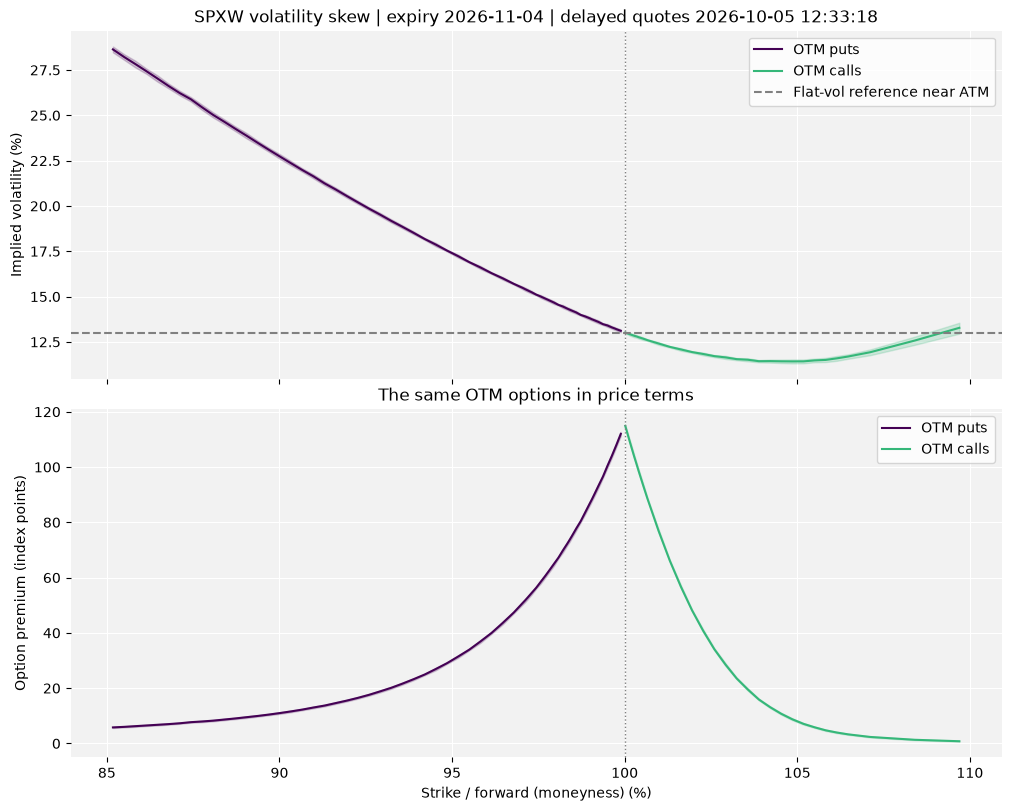

Saved plot and filtered quote table in /Users/peter.paton/Documents/other-projects-local/natenberg/spx


In [4]:
fig, (iv_ax, price_ax) = plt.subplots(
    2, 1, sharex=True, figsize=(10, 8), layout="constrained"
)
for kind, label, color in [("P", "OTM puts", "#440154"), ("C", "OTM calls", "#35b779")]:
    wing = smile.loc[smile["kind"] == kind]
    x = 100 * wing["moneyness"].to_numpy()
    iv_ax.plot(x, 100 * wing["mid_iv"], color=color, label=label, linewidth=1.5)
    iv_ax.fill_between(
        x, 100 * wing["bid_iv"], 100 * wing["ask_iv"], color=color, alpha=0.20
    )
    price_ax.plot(x, wing["mid"], color=color, label=label)
    price_ax.fill_between(x, wing["bid"], wing["ask"], color=color, alpha=0.20)

near_atm = smile.iloc[np.argmin(abs(smile["moneyness"] - 1))]
iv_ax.axhline(
    100 * near_atm["mid_iv"],
    color="grey",
    linestyle="--",
    label="Flat-vol reference near ATM",
)
iv_ax.set(
    title=f"SPXW volatility skew | expiry {expiry.date()} | delayed quotes {payload['timestamp']}",
    ylabel="Implied volatility (%)",
)
price_ax.set(
    xlabel="Strike / forward (moneyness) (%)",
    ylabel="Option premium (index points)",
    title="The same OTM options in price terms",
)
for ax in (iv_ax, price_ax):
    ax.axvline(100, color="grey", linestyle=":", linewidth=1)
    ax.set_facecolor("#f2f2f2")
    ax.grid(color="white")
    ax.set_axisbelow(True)
    ax.legend()
    for spine in ax.spines.values():
        spine.set_visible(False)
figure_path = spx_dir / "volatility_smile.png"
fig.savefig(figure_path, dpi=160)
plt.show()

export_columns = [
    "option",
    "expiry",
    "kind",
    "strike",
    "bid",
    "ask",
    "bid_size",
    "ask_size",
    "mid",
    "relative_spread",
    "moneyness",
    "bid_iv",
    "mid_iv",
    "ask_iv",
    "iv",
    "volume",
    "open_interest",
]
smile[export_columns].to_csv(spx_dir / "volatility_smile_quotes.csv", index=False)
print("Saved plot and filtered quote table in", spx_dir)

## Read the result

- Compare the lower-strike put wing with the higher-strike call wing. A higher downside wing means protection is priced more richly in IV terms.
- Wider shading means greater uncertainty from the bid-ask spread. Filtered-out quotes may be even less informative.
- Demand for protection, compensation required by sellers, and the market's pricing of jumps and tail risk all contribute. The curve alone does not identify their separate effects.
- This is one expiry's curve, not a volatility surface or the Cboe SKEW Index. A surface repeats the exercise across expiries, with consistent forward, discount and settlement conventions.

For a new snapshot, rerun all cells with `refresh_quotes = True`. Inspect the printed response and underlying timestamps before calling the data current. The index last-trade field may lag option trading; the endpoint does not supply an individual timestamp for each bid and ask.